# What is every cohort's curve on 53,089 members, and what is the dashboard's 38 made of?

**Week 4, Thursday, chapter 2 of 3 (L2 and L3).** Chapter 1 counted twelve members by hand:
each signup group fell as it aged, the August sale-week members kept 1 of 5 in month one, and
the dashboard's way of counting read 2 of 7 in August and in September, because it leaves a
member out until her second month. This notebook does the same on every member.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for
> this class.*

**The ticket. Zomato Gold, Chennai, the membership and the app's order flow.** The membership
dashboard reports month-two retention for Chennai, the share of members two or more months past
their signup month who ordered in the month, as flat at 38 percent for June, July, August and
September 2026. Each signup cohort's own curve falls with age, and each cohort's month-one rate is
lower than the one before: January 58 percent, April 53, July 49, and August 31. The August cohort,
13,000 members, 2.6 times the 5,000 a month of January to July, grew out of a sale week with a
discounted first month. On Monday 14 September 2026 a new checkout flow shipped on Android; since
then members' add-to-cart to order conversion on Android fell from 58 to 44 percent, while members
on iOS went from 57 to 56 and non-members on Android from 52 to 51. **The ask, due Friday:** is it
a cohort problem or an everyone problem, which funnel stage owns the loss, and what should be fixed
first, with the evidence.

**Who needs the answer.** The membership lead, who reads 38 percent each month and is about to
report "nothing changed". If the flat number is hiding falling cohorts and a weak August cohort,
the fix waits a month too long.

**The questions on the way.**

1. What does each cohort keep, month by month, on the full data?
2. What does the dashboard print from June to September, counted directly?
3. What is September's 38 made of, cohort by cohort?
4. What is outside the count, and what would the number read with it in?

In [1]:
# Load the members and their months; count a member as active in a month when she ordered.
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print(("PASS  " if ok else "FAIL  ") + name)

members = pd.read_csv("../data/C2_W04_D04_members_STUDENT.csv")
mm = pd.read_csv("../data/C2_W04_D04_member_months_STUDENT.csv")
mm = mm.merge(members[["member_id", "cohort_month", "signup_channel"]], on="member_id")
mm["active"] = mm["orders"] > 0
print(f"{len(members):,} members, {len(mm):,} member-months")
check("one member_months row per member per month since she joined",
      not mm.duplicated(["member_id", "month"]).any())

53,089 members, 241,492 member-months
PASS  one member_months row per member per month since she joined


## How old is each member in each month?

Age is months since the signup month: the signup month is month zero, the next calendar month
is month one. Two year-and-month strings become one count of months each, and the gap is the age.

In [2]:
# Months since joining: each year-month as year x 12 + month, then the gap between the two.
month_n = mm["month"].str[:4].astype(int) * 12 + mm["month"].str[5:].astype(int)
cohort_n = mm["cohort_month"].str[:4].astype(int) * 12 + mm["cohort_month"].str[5:].astype(int)
mm["age"] = month_n - cohort_n
mm.head()

,member_id,month,orders,cohort_month,signup_channel,active,age
0,ZG00001,2026-01,1,2026-01,organic,True,0
1,ZG00001,2026-02,1,2026-01,organic,True,1
2,ZG00001,2026-03,2,2026-01,organic,True,2
3,ZG00001,2026-04,1,2026-01,organic,True,3
4,ZG00001,2026-05,3,2026-01,organic,True,4


## What does each cohort keep, month by month, on the full data?

A **cohort** is the members who joined in the same calendar month. One `pivot_table` puts the
cohorts on the rows and the ages on the columns; each cell is the share of the cohort that
ordered at that age. **Predict before you run.** After month one, which way does each row run?

- a) Up, as members settle into the habit
- b) Flat, which is why the dashboard is flat
- c) Down, a big step after month one and then a slow slide
- d) Up and then down

In [3]:
# The cohort table: share of each cohort that ordered at each age, month one onwards.
tri = mm[mm["age"] >= 1].pivot_table(index="cohort_month", columns="age", values="active", aggfunc="mean")
(100 * tri).round(1)

age,1,2,3,4,5,6,7,8
cohort_month,,,,,,,,
2026-01,58.0,38.7,38.4,38.1,37.8,37.5,37.2,36.9
2026-02,56.0,38.6,38.3,38.0,37.7,37.4,37.1,NaN
2026-03,55.0,38.6,38.4,38.0,37.8,37.5,NaN,NaN
2026-04,53.0,38.6,38.3,38.0,37.7,NaN,NaN,NaN
2026-05,52.0,38.7,38.4,38.1,NaN,NaN,NaN,NaN
2026-06,50.0,38.9,38.6,NaN,NaN,NaN,NaN,NaN
2026-07,49.0,38.5,NaN,NaN,NaN,NaN,NaN,NaN
2026-08,31.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


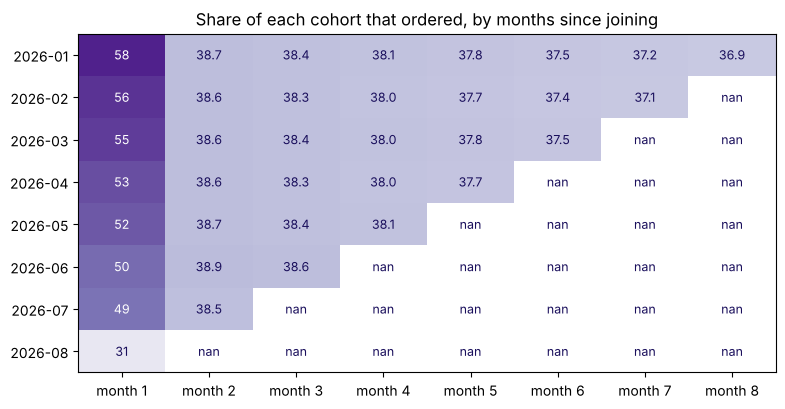

PASS  every cohort falls at every age it has reached
PASS  month one runs 58, 56, 55, 53, 52, 50, 49 and 31 percent


In [4]:
# The same table as a picture: one row per cohort, falling left to right.
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.imshow(tri.values, cmap="Purples", vmin=0.25, vmax=0.62, aspect="auto")
for (i, j), v in pd.DataFrame(tri.values).stack().items():
    ax.text(j, i, f"{100 * v:.0f}" if j == 0 else f"{100 * v:.1f}", ha="center", va="center",
            color="white" if v > 0.45 else "#1A0F5C", fontsize=9)
ax.set_xticks(range(tri.shape[1]), [f"month {k}" for k in tri.columns])
ax.set_yticks(range(len(tri)), tri.index)
ax.set_title("Share of each cohort that ordered, by months since joining"); plt.show()
falling = all((row.dropna().diff().dropna() < 0).all() for _, row in tri.iterrows())
check("every cohort falls at every age it has reached", falling)
check("month one runs 58, 56, 55, 53, 52, 50, 49 and 31 percent",
      [round(100 * v) for v in tri[1]] == [58, 56, 55, 53, 52, 50, 49, 31])

**What happened.** The answer is c. Every cohort drops sharply from month one to month two,
to about 38.5 percent, then slides about 0.3 points a month. Each cohort also starts lower than
the one before: 58 percent in January's month one, 49 in July's, and 31 in August's. Drawn as
lines, the curves fall on top of each other after month one.

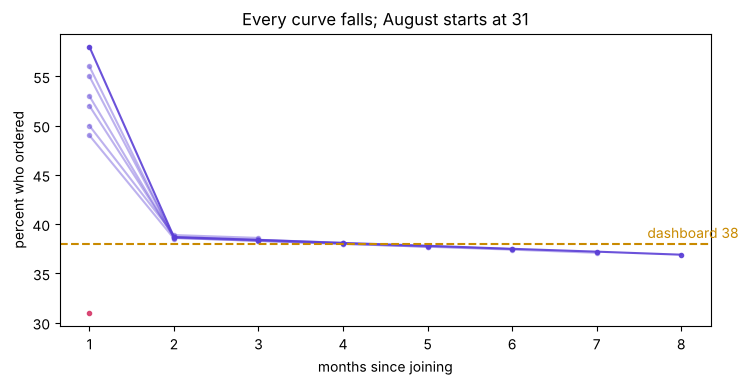

In [5]:
# The curves: one line per cohort, month one on the left.
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for c, row in tri.iterrows():
    row = row.dropna()
    ax.plot(row.index, 100 * row.values, marker="o", ms=3,
            color="#D63A6A" if c == "2026-08" else "#5B3FD6", alpha=0.9 if c in ("2026-01", "2026-08") else 0.4)
ax.axhline(38, ls="--", color="#C98A00"); ax.text(7.6, 38.6, "dashboard 38", color="#C98A00")
ax.set_xlabel("months since joining"); ax.set_ylabel("percent who ordered")
ax.set_title("Every curve falls; August starts at 31"); plt.show()

## What does the dashboard print from June to September, counted directly?

The dashboard takes, in each reporting month, every member two or more months past her signup
month and asks what share ordered. **Predict before you run.** With every cohort falling, what
does it print from June to September?

- a) A fall of two or three points a month
- b) About 38 percent every month
- c) A rise, because new cohorts keep joining
- d) Flat until September, then a drop when the August cohort arrives

In [6]:
# The dashboard, counted directly: members aged two or more, and the share who ordered.
report = ["2026-06", "2026-07", "2026-08", "2026-09"]
dash = (mm[mm["month"].isin(report) & (mm["age"] >= 2)]
        .groupby("month")["active"].agg(counted="size", ordered="sum", rate="mean"))
dash["rate"] = (100 * dash["rate"]).round(1)
dash

,counted,ordered,rate
month,,,
2026-06,20217,7722,38.2
2026-07,25122,9558,38.0
2026-08,29943,11359,37.9
2026-09,35000,13218,37.8


**What happened.** The answer is b: 38.2, 38.0, 37.9 and 37.8 percent, which the dashboard
prints as 38 every month.

**The plausible wrong answer.** "Month-two retention is 38 percent and flat, so nothing
changed." The decision it would mislead: the August cohort gets no action and the dashboard stays
as the month's headline. **Why it is wrong.** The 38 is an average over cohorts of different
ages, weighted by their sizes, and it only counts a member from her second month. Each month a
new cohort enters the count at about 38.5 percent, just above the older cohorts' slow slide,
so the average holds while every cohort falls. **The check** is to take the number apart.

## What is September's 38 made of, cohort by cohort?

**Your turn.** In the empty cell below, take September's rows with age two or more, group them
by `cohort_month`, and compute each cohort's size and rate. Then compute the size-weighted
average of the rates and compare it with the 37.8 above. The lines to type:

```python
sep = mm[(mm["month"] == "2026-09") & (mm["age"] >= 2)]
parts = sep.groupby("cohort_month")["active"].agg(size="size", rate="mean")
(parts["size"] * parts["rate"]).sum() / parts["size"].sum()
```

**Check your cell against this one.** The table below is the same decomposition for all four
reporting months: each month's 38 is the weighted average of the cohorts it counts, and the
second route agrees with the direct count to the last digit.

In [7]:
# The second route: each month's number as the size-weighted average of its cohorts' rates.
for month in report:
    parts = (mm[(mm["month"] == month) & (mm["age"] >= 2)]
             .groupby("cohort_month")["active"].agg(size="size", rate="mean"))
    weighted = (parts["size"] * parts["rate"]).sum() / parts["size"].sum()
    direct = mm[(mm["month"] == month) & (mm["age"] >= 2)]["active"].mean()
    print(month, f"{100 * weighted:.2f} weighted = {100 * direct:.2f} direct,", len(parts), "cohorts")
    check(f"{month}: the weighted average equals the direct count", abs(weighted - direct) < 1e-12)
parts.assign(rate=(100 * parts["rate"]).round(1))

2026-06 38.20 weighted = 38.20 direct, 4 cohorts
PASS  2026-06: the weighted average equals the direct count
2026-07 38.05 weighted = 38.05 direct, 5 cohorts
PASS  2026-07: the weighted average equals the direct count
2026-08 37.94 weighted = 37.94 direct, 6 cohorts
PASS  2026-08: the weighted average equals the direct count
2026-09 37.77 weighted = 37.77 direct, 7 cohorts
PASS  2026-09: the weighted average equals the direct count


,size,rate
cohort_month,,
2026-01,4854,36.9
2026-02,5055,37.1
2026-03,5449,37.5
2026-04,4859,37.7
2026-05,4905,38.1
2026-06,4821,38.6
2026-07,5057,38.5


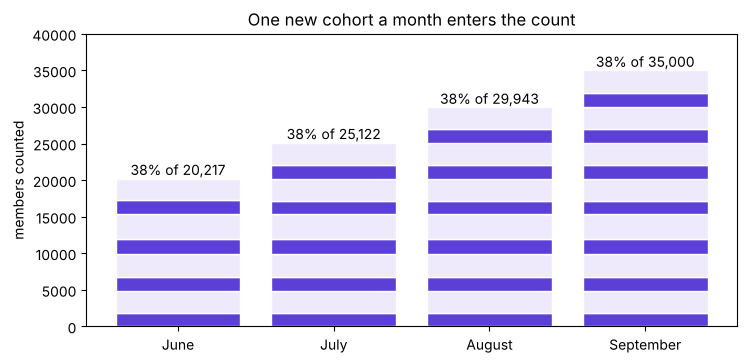

In [8]:
# Each month's count drawn as stacked cohorts: dark ordered, light did not.
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for x, month in enumerate(report):
    parts = mm[(mm["month"] == month) & (mm["age"] >= 2)].groupby("cohort_month")["active"].agg(["size", "sum"])
    bottom = 0
    for c, r in parts.iterrows():
        ax.bar(x, r["sum"], bottom=bottom, color="#5B3FD6", edgecolor="white")
        ax.bar(x, r["size"] - r["sum"], bottom=bottom + r["sum"], color="#EEEAFB", edgecolor="white")
        bottom += r["size"]
    ax.text(x, bottom + 500, f"{parts['sum'].sum() / bottom:.0%} of {bottom:,}", ha="center")
ax.set_xticks(range(4), ["June", "July", "August", "September"]); ax.set_ylim(0, 40000)
ax.set_ylabel("members counted"); ax.set_title("One new cohort a month enters the count"); plt.show()

## What is outside the count, and what would the number read with it in?

In September the dashboard counts the seven cohorts from January to July, 35,000 members. The
August cohort, 13,000 members in its month one, is not in it. **Predict before you run.**
Counting everyone who joined before September, what does September read?

- a) Still 38 percent
- b) About 36 percent
- c) About 31 percent, August's rate
- d) About 49 percent, the organic August members' rate

In [9]:
# September counted two ways, and the August cohort split by how its members joined.
sep_all = mm[(mm["month"] == "2026-09") & (mm["age"] >= 1)]
print(f"everyone who joined before September: {sep_all['active'].sum():,} of {len(sep_all):,} "
      f"= {sep_all['active'].mean():.1%}")
aug = mm[(mm["cohort_month"] == "2026-08") & (mm["age"] == 1)].groupby("signup_channel")["active"].agg(["size", "mean"])
print(aug.assign(mean=(100 * aug["mean"]).round(1)))
check("counting everyone, September reads about 36 percent", round(100 * sep_all["active"].mean()) == 36)
check("the sale-week members, not August as a whole, sit low",
      aug.loc["sale", "mean"] < 0.25 and abs(aug.loc["organic", "mean"] - tri.loc["2026-07", 1]) < 0.01)

everyone who joined before September: 17,248 of 48,000 = 35.9%
                size  mean
signup_channel            
organic         4973  49.0
sale            8027  19.8
PASS  counting everyone, September reads about 36 percent
PASS  the sale-week members, not August as a whole, sit low


**What happened.** The answer is b: 17,248 of 48,000, 35.9 percent, printed as 36. The two
readings differ by who is counted, and the August cohort is the whole difference. Split by how
its members joined, the 4,973 organic August members kept 49 percent in month one, July's rate,
while the 8,027 sale-week members kept 20 percent. When the August cohort reaches its second
month in October, it enters the dashboard. If it falls from month one to month two as July's
did, it enters at about 20 percent, and the dashboard drops to about 33 (between 32 and 34 if
it enters anywhere from 17 to 24 percent).

**The questions, answered.** (1) Every cohort falls with age, from 58 to 49 percent in month
one across January to July and 31 for August, then to about 38.5 and slowly down. (2) The
dashboard prints 38 from June to September. (3) September's 38 is the size-weighted average of
seven cohorts, and the weighted average equals the direct count. (4) The 13,000-member sale
cohort is outside the count; with it in, September reads 36.